# Observed Magnitude-Squared Coherence

The default `REFERENCE_KEYS = ("CWV", "W")` calculates CWV, W1, and W2 in one run.
All selected fields use the same common daily record and grid. Results and domain
means are indexed by reference, then heating component; the plotting cells show
both the omega comparison and the CWV spectrum for `MSC_PLOT_SOURCE`.


## Import package

In [46]:
import os
import sys
from pathlib import Path
from datetime import datetime
from collections.abc import Sequence
from dataclasses import dataclass

CPU_THREADS = 4
for thread_variable in (
    "OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS",
    "BLIS_NUM_THREADS", "NUMEXPR_NUM_THREADS",
):
    os.environ[thread_variable] = str(CPU_THREADS)

import netCDF4 as nc
import numpy as np
from matplotlib import pyplot as plt
from matplotlib.axes import Axes
from matplotlib.figure import Figure
from threadpoolctl import threadpool_limits
from itertools import product

THREADPOOL_LIMITER = threadpool_limits(limits=CPU_THREADS)
sys.path.insert(0, "/home/b11209013/Manuscript_Prep/KW_CRI/src")
import preprocessing as preproc       #type: ignore
import cross_spectrum_ana as workflow #type: ignore
import spectrum                       #type: ignore

# Modified: apply the notebook stylesheet using the project location, independent of the working directory.
STYLE_PATH = Path(preproc.__file__).resolve().parents[1] / "Code" / "ERA5" / "scientific.mplstyle"
plt.style.use(STYLE_PATH)

MeridionalComponent = workflow.MeridionalComponent

## Helper Functions

### Load data

In [47]:
def load_field(
    FILE_PATH: Path,
    VARIABLE_KEY: str,
    LATITUDE_BOUNDS: tuple[float, float],
    START_DATE: str | None,
    END_DATE: str | None,
) -> tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
    """Load a daily field, with latitude sorted south to north.

    START_DATE is inclusive and END_DATE is exclusive, as in Qr_Prec.ipynb.
    W retains its pressure-level axis for the subsequent EOF calculation.
    """
    with nc.Dataset(FILE_PATH) as dataset:
        dates: np.ndarray = preproc.convert_time(dataset.variables["time"])
        latitude: np.ndarray = preproc.as_float_array(dataset.variables["lat"][:])
        longitude: np.ndarray = preproc.as_float_array(dataset.variables["lon"][:])
        date_mask: np.ndarray = np.ones(dates.size, dtype=bool)
        
        if START_DATE is not None:
            date_mask &= dates >= START_DATE
        if END_DATE is not None:
            date_mask &= dates < END_DATE
        
        latitude_mask: np.ndarray = (latitude >= LATITUDE_BOUNDS[0]) & (latitude <= LATITUDE_BOUNDS[1])

        variable = dataset.variables[VARIABLE_KEY]
        if VARIABLE_KEY == "W":
            field: np.ndarray = preproc.as_float_array(variable[date_mask, :, latitude_mask, :])
        else:
            field = preproc.as_float_array(variable[date_mask, latitude_mask, :])

    latitude_order: np.ndarray = np.argsort(latitude[latitude_mask])
    return (
        np.take(field, latitude_order, axis=-2),
        dates[date_mask],
        latitude[latitude_mask][latitude_order],
        longitude,
    )

### Load Analysis Field

In [48]:
# Modified: load the selected references together and align every field to the same dates/grid.
def load_analysis_fields(
    DATA_PATH: Path,
    LATITUDE_BOUNDS: tuple[float, float],
    REFERENCE_KEYS: tuple[str, ...],
    SOURCE_NAME: str,
    START_DATE: str | None,
    END_DATE: str | None,
) -> tuple[dict[str, np.ndarray], dict[str, np.ndarray]]:
    """Load heating once and return reference fields on their shared daily record."""
    # Modified: allow CWV and W together, or either reference alone, without duplicate keys.
    if not REFERENCE_KEYS or len(set(REFERENCE_KEYS)) != len(REFERENCE_KEYS):
        raise ValueError("REFERENCE_KEYS must contain at least one unique reference.")
    if not set(REFERENCE_KEYS).issubset({"CWV", "W"}):
        raise ValueError("REFERENCE_KEYS may contain CWV and/or W.")
    if SOURCE_NAME not in {"QR", "LW", "SW", "ALL"}:
        raise ValueError("SOURCE_NAME must be QR, LW, SW, or ALL.")

    lw_heating, dates, latitude, longitude = load_field(
        DATA_PATH / "CERES" / "column_LW_rm3harm.nc", "column_LW",
        LATITUDE_BOUNDS, START_DATE, END_DATE,
    )
    sw_heating, sw_dates, sw_latitude, sw_longitude = load_field(
        DATA_PATH / "CERES" / "column_SW_rm3harm.nc", "column_SW",
        LATITUDE_BOUNDS, START_DATE, END_DATE,
    )

    # Modified: check each reference against the same CERES latitude/longitude grid.
    def check_grid(name: str, lat: np.ndarray, lon: np.ndarray) -> None:
        if (lat.shape != latitude.shape or lon.shape != longitude.shape
                or not np.allclose(lat, latitude) or not np.allclose(lon, longitude)):
            raise ValueError(f"{name} and LW must use the same latitude/longitude grid.")

    check_grid("SW", sw_latitude, sw_longitude)
    reference_fields = {}
    reference_dates = {}
    common_dates = np.intersect1d(dates, sw_dates)
    for ref_key in REFERENCE_KEYS:
        reference_file = DATA_PATH / "ERA5_GRIB" / "Data" / "regrid" / f"{ref_key}.nc"
        field, field_dates, ref_latitude, ref_longitude = load_field(
            reference_file, ref_key, LATITUDE_BOUNDS, START_DATE, END_DATE,
        )
        check_grid(ref_key, ref_latitude, ref_longitude)
        reference_fields[ref_key] = field
        reference_dates[ref_key] = field_dates
        common_dates = np.intersect1d(common_dates, field_dates)

    # Modified: require one continuous daily record shared by LW, SW, CWV, and omega.
    if common_dates.size == 0:
        raise ValueError("No common dates exist for all selected fields.")
    if np.any(np.diff(common_dates.astype("datetime64[D]")) != np.timedelta64(1, "D")):
        raise ValueError("The common dates must form a continuous daily record.")

    def align(field: np.ndarray, field_dates: np.ndarray) -> np.ndarray:
        if np.unique(field_dates).size != field_dates.size:
            raise ValueError("Input fields must contain only one sample per calendar day.")
        _, indices, _ = np.intersect1d(field_dates, common_dates, return_indices=True)
        return field[indices]

    lw_heating = align(lw_heating, dates)
    sw_heating = align(sw_heating, sw_dates)
    reference_fields = {
        ref_key: align(field, reference_dates[ref_key])
        for ref_key, field in reference_fields.items()
    }
    print(
        f"Analyzing {common_dates[0]} through {common_dates[-1]} "
        f"({common_dates.size} shared days); references: {', '.join(REFERENCE_KEYS)}."
    )

    source_fields = {}
    if SOURCE_NAME in {"QR", "ALL"}:
        source_fields["QR"] = lw_heating + sw_heating
    if SOURCE_NAME in {"LW", "ALL"}:
        source_fields["LW"] = lw_heating
    if SOURCE_NAME in {"SW", "ALL"}:
        source_fields["SW"] = sw_heating
    return source_fields, reference_fields


### Calculate coherence square

In [49]:
# Modified: integrate spectral averaging and MSC calculation for one reference.
def calc_mcs(
    source_chunks: dict[str, np.ndarray],
    # Modified: pass one reference's chunk array, rather than the reference dictionary.
    reference_chunks: np.ndarray,
    chunk_size: int,
) -> tuple[
    dict[str, np.ndarray],
    dict[str, dict[str, np.ndarray] | np.ndarray],
]:
    """Return MSC by source and the mean spectra for a single reference.

    Each input chunk array has shape (segment, time, latitude, longitude).
    MSC and mean spectra have shape (frequency, zonal_wavenumber) in FFT order.
    Cross- and auto-spectra are averaged before calculating coherence.
    """
    # calculate segment spectra for each source and reference pair
    cross_by_source, power_by_source, reference_power = workflow.calculate_segment_spectra(
        source_chunks=source_chunks,
        reference_chunks=reference_chunks,
        window_size=chunk_size,
    )

    # average the segment spectra
    mean_cross_spectrum, mean_source_spectrum, mean_reference_spectrum = workflow.average_segment_spectra(
        cross_by_source,
        power_by_source,
        reference_power,
    )

    # calculate MSC for each source
    msc_coherence_squared: dict[str, np.ndarray] = {}
    for src_key in source_chunks.keys():
        msc_coherence_squared[src_key] = spectrum.calculate_squared_coherence(
            mean_cross_spectrum=mean_cross_spectrum[src_key],
            mean_source_power=mean_source_spectrum[src_key],
            mean_reference_power=mean_reference_spectrum,
        )

    # Modified: retain the observed mean cross- and auto-spectra alongside MSC.
    mean_spectra = {
        "cross_spectrum": mean_cross_spectrum,
        "source_power": mean_source_spectrum,
        "reference_power": mean_reference_spectrum,
    }
    return msc_coherence_squared, mean_spectra


## Main Procedure

### Load heating and all selected reference fields


In [50]:
# Configuration
DATA_PATH      : Path                = Path("/data92/b11209013")
LATITUDE_BOUNDS: tuple[float, float] = (-5.0, 5.0)
# Modified: calculate both reference families in one run; either tuple can also contain one key.
REFERENCE_KEYS : tuple[str, ...]     = ("CWV", "W")
SOURCE_NAME    : str                 = "ALL"  # QR, LW, SW, or ALL
DATE_BOUNDS    : tuple[str, str]     = ("2006-01-01", "2018-01-01")
CHUNK_SIZE     : int                 = 96
OVERLAP_SIZE   : int                 = 48

# Modified: load the heating fields once and receive all selected aligned reference fields.
source, reference_fields = load_analysis_fields(
    DATA_PATH=DATA_PATH,
    LATITUDE_BOUNDS=LATITUDE_BOUNDS,
    REFERENCE_KEYS=REFERENCE_KEYS,
    SOURCE_NAME=SOURCE_NAME,
    START_DATE=DATE_BOUNDS[0],
    END_DATE=DATE_BOUNDS[1],
)

# calculate anomalous fields
source_anom: dict[str, np.ndarray] = {
    key: workflow.remove_time_zonal_mean(value)
    for key, value in source.items()
}


Analyzing 2006-01-01 through 2017-12-31 (4383 shared days); references: CWV, W.


### Prepare CWV anomalies and omega EOF components


In [51]:
# Modified: accumulate CWV and both omega PCs instead of replacing the previous reference.
reference_components: dict[str, np.ndarray] = {}
for ref_key, reference in reference_fields.items():
    if ref_key == "W":
        # Modified: preserve the existing omega EOF normalization and PC sign convention.
        nt, nz, ny, nx = reference.shape
        reference_reshape = reference.transpose(1, 0, 2, 3).reshape(nz, -1)
        eofs, pcs = preproc.calculate_eof(reference_reshape, n_components=2)
        reference_components.update({
            f"W{i+1}": pcs[i].reshape(nt, ny, nx)
            if eofs[:, i].max() > 0.1 else -pcs[i].reshape(nt, ny, nx)
            for i in (0, 1)
        })
    else:
        reference_components[ref_key] = workflow.remove_time_zonal_mean(reference)

# Modified: validate every source/reference combination before the shared spectral calculation.
for reference_component in reference_components.values():
    workflow.validate_aligned_fields(source_anom, reference_component)
iter_list: list[tuple[str, str]] = list(product(reference_components.keys(), source_anom.keys()))
print(f"Reference components: {tuple(reference_components)}")


Reference components: ('CWV', 'W1', 'W2')


### Applying Spectral Analysis

In [52]:
# chunking data
# Modified: segment_fields returns NumPy arrays with a leading segment axis.
source_chunks: dict[str, np.ndarray] = workflow.segment_fields(
    source_anom, CHUNK_SIZE, OVERLAP_SIZE
)
reference_chunks: dict[str, np.ndarray] = workflow.segment_fields(
    reference_components, CHUNK_SIZE, OVERLAP_SIZE
)

# calculate coherence square for each pair
iter_list: list[tuple[str, str]] = list(product(
    source_chunks.keys(), reference_chunks.keys()
))

# Modified: initialize results for the per-reference calls to calc_mcs().
msc_coherence_squared: dict[str, dict[str, np.ndarray]] = {}
msc_mean_spectra = {}

for ref_key, reference_data_chunks in reference_chunks.items():
    # Modified: use the helper once per reference and retain both returned results.
    msc_coherence_squared[ref_key], msc_mean_spectra[ref_key] = calc_mcs(
        source_chunks=source_chunks,
        reference_chunks=reference_data_chunks,
        chunk_size=CHUNK_SIZE,
    )


## Visualizing observed MSC

The plots display `msc_coherence_squared[reference_key][source_key]` on a 0-to-1
color scale. Only bins where coherence is mathematically undefined remain blank.
Coordinates and spectra are shifted together, and positive frequencies are displayed.


### Domain Setting

In [64]:
# Frequency coordinates: cycles/day and zonal wavenumber, in FFT order.
msc_first_reference = next(iter(reference_chunks.values()))
msc_frequencies, msc_zonal_wavenumbers = workflow.spectral_coordinates(
    window_size=CHUNK_SIZE,
    n_longitudes=msc_first_reference.shape[-1],
    sampling_interval=1.0,
)

# Modified: select the observed heating component to display in both plotting cells.
MSC_PLOT_SOURCE = "QR"  # "LW" or "SW" can also be selected.

# Modified: align the shifted coordinates and show positive temporal frequencies.
msc_plot_frequencies = np.fft.fftshift(msc_frequencies)
msc_plot_wavenumbers = np.fft.fftshift(msc_zonal_wavenumbers)
msc_positive_frequency = msc_plot_frequencies > 0

# Modified: use the observed MSC on a common 0-to-1 color scale; undefined bins appear white.
msc_plot_cmap = plt.get_cmap("RdBu_r").copy()
msc_plot_cmap.set_bad("white")


### Mean MSC in the wave domains

Use `workflow.average_wave_domain_coherence()` with the same domains and averaging
rule as `Qr_Prec.ipynb`. Each value is the unweighted arithmetic mean of finite
observed MSC bins, not coherence calculated after pooling spectra across the band.

- **Kelvin:** wavenumber 3–8, frequency 1/20–0.3 cycles/day, intersected with the
  Kelvin dispersion band between 8 and 90 m equivalent depth.
- **Rossby (n=1):** wavenumber −8 to −2, frequency 0.02–0.1 cycles/day, intersected
  with the Rossby dispersion band between the same equivalent depths.
- **MJO:** wavenumber 1–3, frequency 1/90–1/30 cycles/day, with no dispersion clipping.

Bounds are inclusive. `EQUIVALENT_DEPTHS` can be changed in the next cell. Results
are stored in `wave_domain_coherence[reference_key][source_key][domain_name]`.
Each entry contains `mean_coherence_squared` and `n_bins`; an empty domain gives
NaN and zero bins. Bin counts are not counts of statistically independent samples.
With 96-day windows, the MJO domain contains only the 48- and 32-day frequency
bins, giving six bins across wavenumbers 1, 2, and 3 when all values are finite.

The table includes every calculated source/reference pair. Each spectrum below
shows dashed domain outlines and the three means for `MSC_PLOT_SOURCE`.


In [65]:
# Modified: use the same equivalent-depth bounds as Qr_Prec.ipynb.
EQUIVALENT_DEPTHS = (8.0, 90.0)

# Modified: reuse the existing domain-averaging helper for every reference/source pair.
wave_domain_coherence = {
    ref_key: {
        src_key: workflow.average_wave_domain_coherence(
            zonal_wavenumbers=msc_zonal_wavenumbers,
            frequencies=msc_frequencies,
            coherence_squared=values,
            equivalent_depths=EQUIVALENT_DEPTHS,
        )
        for src_key, values in source_spectra.items()
    }
    for ref_key, source_spectra in msc_coherence_squared.items()
}

# Modified: display the mean observed MSC and finite bin count in each wave band.
print(f"{'Reference':<12} {'Source':<8} {'Domain':<10} {'Mean MSC':>12} {'Finite bins':>12}")
for ref_key, source_domains in wave_domain_coherence.items():
    for src_key, domains in source_domains.items():
        for domain_name, stats in domains.items():
            print(
                f"{ref_key:<12} {src_key:<8} {domain_name:<10} "
                f"{stats['mean_coherence_squared']:>12.4f} {stats['n_bins']:>12d}"
            )


# Modified: annotate the observed spectra using the shared domain definitions and means.
def annotate_wave_domains(
    axis: Axes,
    domain_statistics: dict,
    equivalent_depths: tuple[float, float],
) -> None:
    """Outline the averaging domains and show their mean MSC, as in Qr_Prec.ipynb."""
    for domain_name, k_bounds, f_bounds, branch in workflow._WAVE_DOMAINS:
        domain_k = np.linspace(*k_bounds, 1001)
        if branch is None:
            lower = np.full_like(domain_k, f_bounds[0])
            upper = np.full_like(domain_k, f_bounds[1])
        else:
            curves = [
                workflow.dispersion_relation(domain_k, depth)[branch]
                for depth in equivalent_depths
            ]
            lower = np.maximum(np.minimum(curves[0], curves[1]), f_bounds[0])
            upper = np.minimum(np.maximum(curves[0], curves[1]), f_bounds[1])
        if np.any(lower < upper):
            axis.fill_between(
                domain_k, lower, upper, where=lower <= upper,
                interpolate=True, facecolor="none", edgecolor="black",
                linewidth=1.5, linestyle="--", zorder=4,
            )

    summary = "Mean MSC\n" + "\n".join(
        f"{domain_name:<7}: {stats['mean_coherence_squared']:.3f}"
        for domain_name, stats in domain_statistics.items()
    )
    # Modified: inherit annotation font family and size from scientific.mplstyle.
    axis.text(
        0.98, 0.98, summary, transform=axis.transAxes,
        ha="right", va="top", multialignment="left",
        bbox={"facecolor": "white", "edgecolor": "gray", "alpha": 0.9},
        zorder=5,
    )


Reference    Source   Domain         Mean MSC  Finite bins
CWV          QR       Kelvin           0.3236           96
CWV          QR       Rossby           0.4434           33
CWV          QR       MJO              0.5729            6
CWV          LW       Kelvin           0.2821           96
CWV          LW       Rossby           0.3250           33
CWV          LW       MJO              0.5104            6
CWV          SW       Kelvin           0.0425           96
CWV          SW       Rossby           0.3091           33
CWV          SW       MJO              0.2196            6
W1           QR       Kelvin           0.5503           96
W1           QR       Rossby           0.5320           33
W1           QR       MJO              0.6583            6
W1           LW       Kelvin           0.5415           96
W1           LW       Rossby           0.5111           33
W1           LW       MJO              0.6360            6
W1           SW       Kelvin           0.0434           

### For W1 and W2

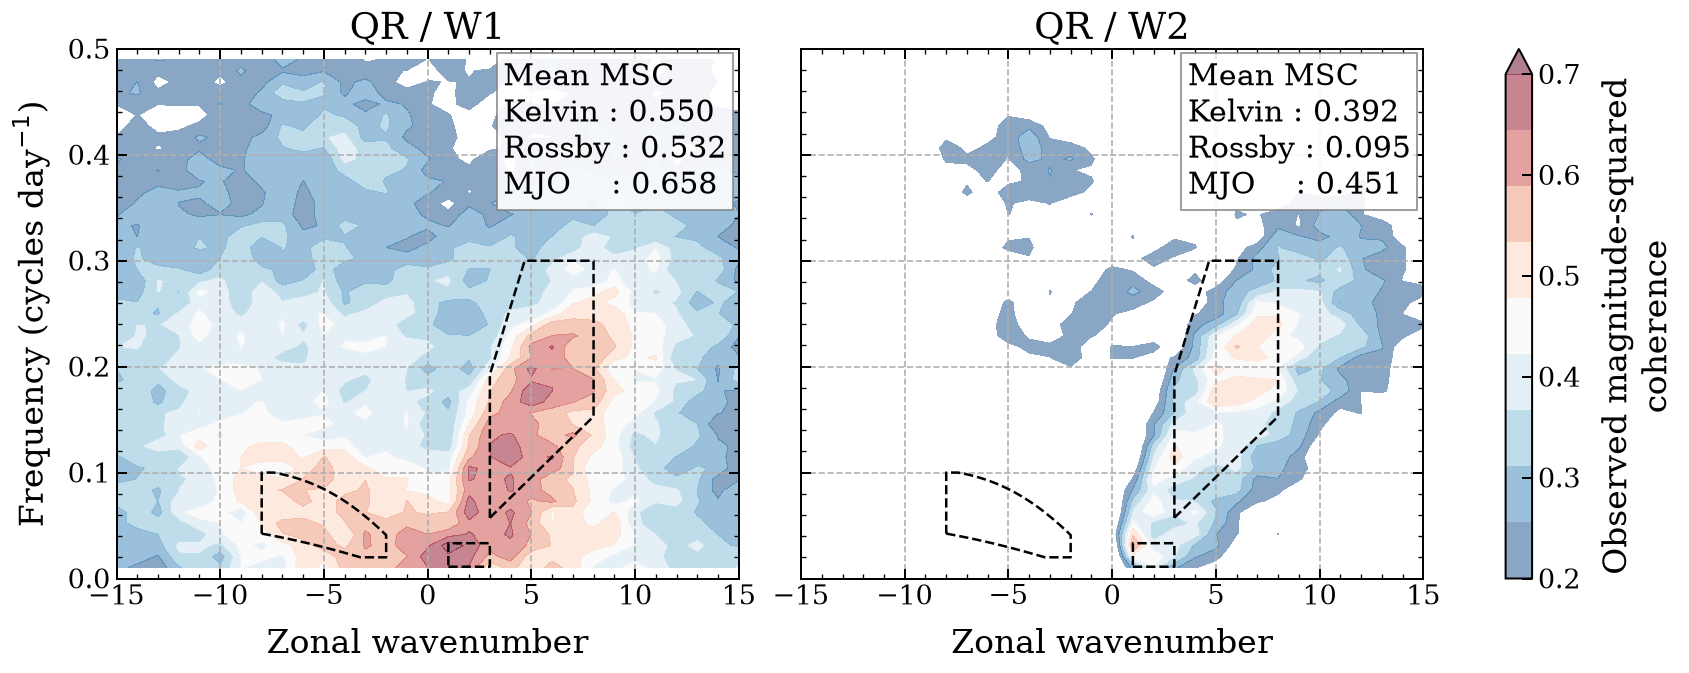

In [79]:
# Modified: render omega whenever its observed results are present in the combined run.
if any(key in msc_coherence_squared for key in ("W1", "W2")):
    # Modified: select the omega references from the observed MSC results.
    msc_omega_plot_keys = [
        key for key in ("W1", "W2") if key in msc_coherence_squared
    ]
    if not msc_omega_plot_keys:
        raise ValueError("Calculate the observed W1/W2 MSC before plotting omega.")
    # Modified: let scientific.mplstyle control the figure size and DPI.
    fig, axes = plt.subplots(
        1, len(msc_omega_plot_keys),
        sharex=True, sharey=True, squeeze=False, constrained_layout=True,
    )
    for axis, ref_key in zip(axes[0], msc_omega_plot_keys):
        # Modified: plot the complete observed MSC for the current reference/source pair.
        observed_plot = np.fft.fftshift(
            msc_coherence_squared[ref_key][MSC_PLOT_SOURCE], axes=(0, 1),
        )[msc_positive_frequency]
        msc_mesh = axis.contourf(
            msc_plot_wavenumbers,
            msc_plot_frequencies[msc_positive_frequency],
            np.ma.masked_invalid(observed_plot),
            levels=np.linspace(0.2, 0.7, 10),
            cmap=msc_plot_cmap, extend="max", alpha=0.5
        )
        # Modified: display the domain means and frames for this reference/source pair.
        annotate_wave_domains(
            axis, wave_domain_coherence[ref_key][MSC_PLOT_SOURCE], EQUIVALENT_DEPTHS,
        )
        # Modified: label the observed source/reference spectrum.
        axis.set(
            title=f"{MSC_PLOT_SOURCE} / {ref_key}",
            xlim=(-15, 15), ylim=(0, 0.5), xlabel="Zonal wavenumber",
        )
        axis.grid(True, linestyle="--", linewidth=1)
    axes[0, 0].set_ylabel("Frequency (cycles day$^{-1}$)")
    # Modified: wrap the colorbar label to fit the stylesheet's larger fonts.
    w_cbar = fig.colorbar(msc_mesh, ax=axes[0], label="Observed magnitude-squared\ncoherence")
    w_cbar.set_ticks(list(np.linspace(0.2, 0.7, 6)))
    plt.show()


### For CWV

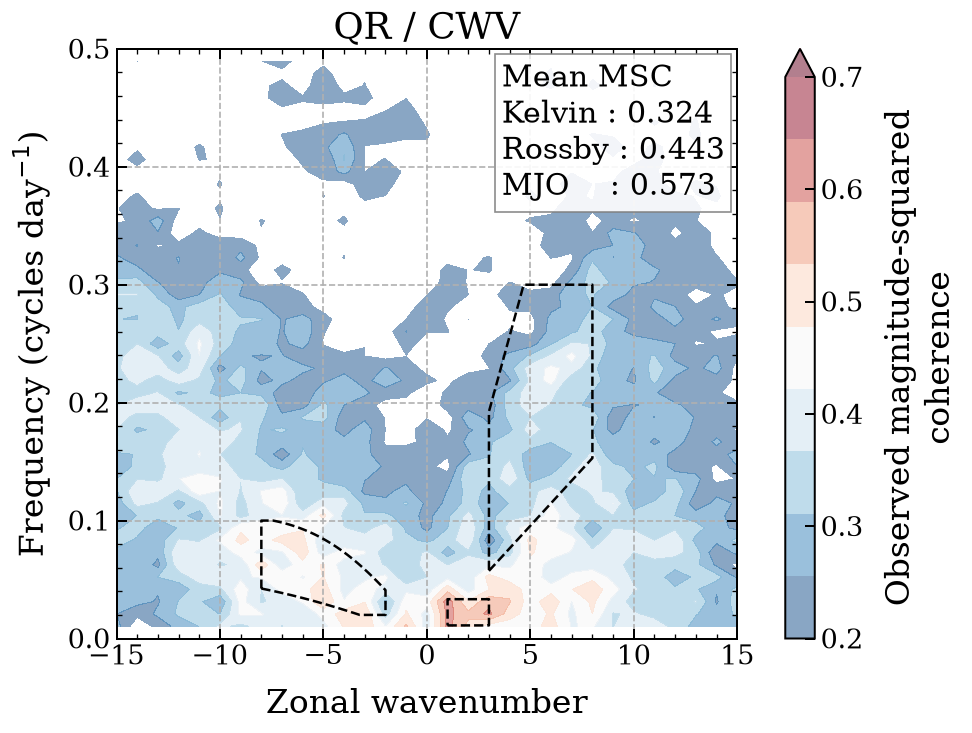

In [80]:
# Modified: render CWV independently of the omega plotting cell.
if "CWV" in msc_coherence_squared:
    # Modified: use the observed CWV spectrum calculated by calc_mcs().
    if "CWV" not in msc_coherence_squared:
        raise ValueError("Calculate the observed CWV MSC before plotting CWV.")
    # Modified: let scientific.mplstyle control the figure size and DPI.
    fig, ax = plt.subplots(1, 1, figsize=(8, 6), constrained_layout=True)

    # Modified: plot all observed CWV MSC values for the selected source.
    observed_plot = np.fft.fftshift(
        msc_coherence_squared["CWV"][MSC_PLOT_SOURCE], axes=(0, 1),
    )[msc_positive_frequency]
    cwv_ctf = ax.contourf(
        msc_plot_wavenumbers,
        msc_plot_frequencies[msc_positive_frequency],
        np.ma.masked_invalid(observed_plot),
        levels=np.linspace(0.2, 0.7, 10), 
        cmap=msc_plot_cmap,
        extend="max", alpha=0.5
    )
    # Modified: display the CWV domain means and the matching averaging frames.
    annotate_wave_domains(
        ax, wave_domain_coherence["CWV"][MSC_PLOT_SOURCE], EQUIVALENT_DEPTHS,
    )
    
    # Modified: label the observed source/reference spectrum.
    ax.set(
        title=f"{MSC_PLOT_SOURCE} / CWV",
        xlim=(-15, 15), ylim=(0, 0.5),
        xlabel="Zonal wavenumber", ylabel="Frequency (cycles day$^{-1}$)",
    )
    ax.grid(True, linestyle="--", linewidth=1)
    # Modified: wrap the colorbar label to fit the stylesheet's larger fonts.
    cwv_cbar = fig.colorbar(cwv_ctf, ax=ax, label="Observed magnitude-squared\ncoherence")
    cwv_cbar.set_ticks(list(np.linspace(0.2, 0.7, 6)))
    plt.show()
